In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn lightgbm


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error
from lightgbm import LGBMRegressor

import warnings
warnings.filterwarnings("ignore")

In [4]:
df = pd.read_csv("city_hourly_demand.csv")

print("First 5 rows:")
display(df.head())

print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

First 5 rows:


,timestamp,demand_mw,temperature_c,humidity_pct,rainfall_mm,forecast_temp_c,holiday_flag
0,2025-03-09 02:00:00,1544.63,32.16,59.67,0.00,32.54,No
1,2025-01-31 20:00:00,2235.89,31.84,66.28,0.00,31.61,No
2,2023-10-26 04:00:00,1474.85,23.16,80.19,0.00,25.51,No
3,2024-11-24 18:00:00,2137.12,25.71,72.36,0.00,26.02,No
4,2024-03-10 12:00:00,1820.34,29.23,68.27,0.74,27.82,No


Dataset shape: (17640, 7)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 17640 entries, 0 to 17639
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   timestamp        17640 non-null  str    
 1   demand_mw        17640 non-null  float64
 2   temperature_c    17380 non-null  float64
 3   humidity_pct     17290 non-null  float64
 4   rainfall_mm      17640 non-null  float64
 5   forecast_temp_c  17500 non-null  float64
 6   holiday_flag     17640 non-null  str    
dtypes: float64(5), str(2)
memory usage: 1.3 MB


In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate timestamps:")
print(df["timestamp"].duplicated().sum())

Missing values:
timestamp            0
demand_mw            0
temperature_c      260
humidity_pct       350
rainfall_mm          0
forecast_temp_c    140
holiday_flag         0
dtype: int64

Duplicate rows:
164

Duplicate timestamps:
201


In [6]:
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

df = df.dropna(subset=["timestamp"])

df["holiday_flag"] = (
    df["holiday_flag"].astype(str).str.strip().str.lower()
    .replace({
        "y": "yes", "n": "no",
        "1": "yes", "0": "no"
    })
)

df["holiday_flag"] = df["holiday_flag"].map({
    "yes": 1,
    "no": 0
})

In [7]:
fahrenheit = df["temperature_c"] > 50

df.loc[fahrenheit, "temperature_c"] = (
    df.loc[fahrenheit, "temperature_c"] - 32
) * 5 / 9

df.loc[~df["humidity_pct"].between(0, 100), "humidity_pct"] = np.nan

df.loc[df["rainfall_mm"] < 0, "rainfall_mm"] = np.nan

df.loc[~df["temperature_c"].between(-5, 55), "temperature_c"] = np.nan

df.loc[~df["forecast_temp_c"].between(-5, 55), "forecast_temp_c"] = np.nan

df.loc[df["demand_mw"] <= 0, "demand_mw"] = np.nan

In [8]:
df = df.drop_duplicates()

df = df.sort_values("timestamp")

df = df.groupby("timestamp", as_index=False).agg({
    "demand_mw": "median",
    "temperature_c": "median",
    "humidity_pct": "median",
    "rainfall_mm": "max",
    "forecast_temp_c": "median",
    "holiday_flag": "max"
})

df = df.set_index("timestamp").asfreq("h")

print("Shape after timestamp correction:", df.shape)

Shape after timestamp correction: (17544, 6)


In [9]:
for col in ["temperature_c", "humidity_pct", "forecast_temp_c"]:
    df[col] = df[col].interpolate(method="time", limit=6)
    df[col] = df[col].fillna(df[col].median())

df["rainfall_mm"] = df["rainfall_mm"].fillna(0)

df["holiday_flag"] = df["holiday_flag"].ffill().bfill().fillna(0)

df["demand_mw"] = df["demand_mw"].interpolate(method="time", limit=3)
df["demand_mw"] = df["demand_mw"].fillna(df["demand_mw"].median())

df = df.reset_index()

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
timestamp          0
demand_mw          0
temperature_c      0
humidity_pct       0
rainfall_mm        0
forecast_temp_c    0
holiday_flag       0
dtype: int64


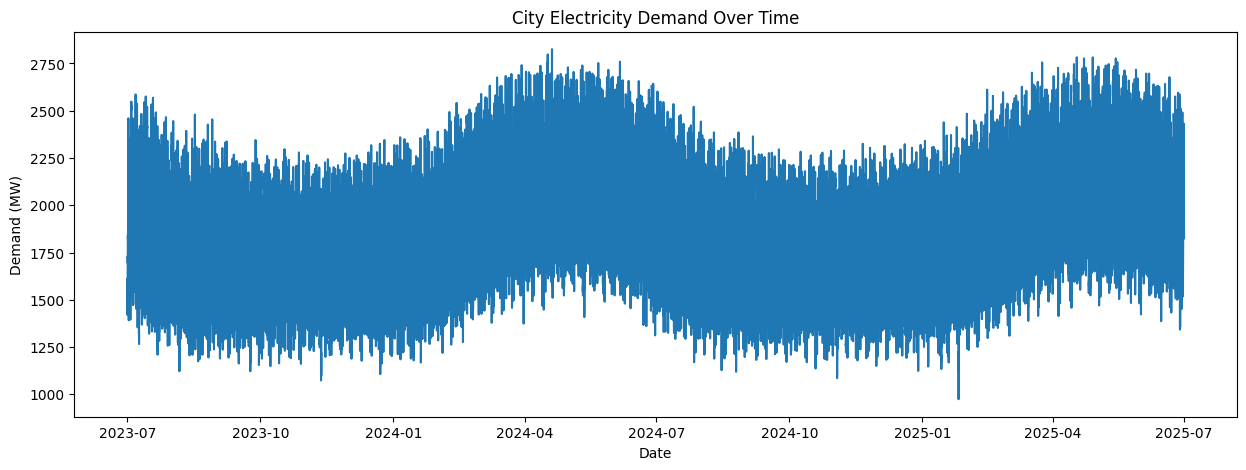

In [10]:
plt.figure(figsize=(15,5))

plt.plot(df["timestamp"], df["demand_mw"])

plt.title("City Electricity Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")

plt.show()

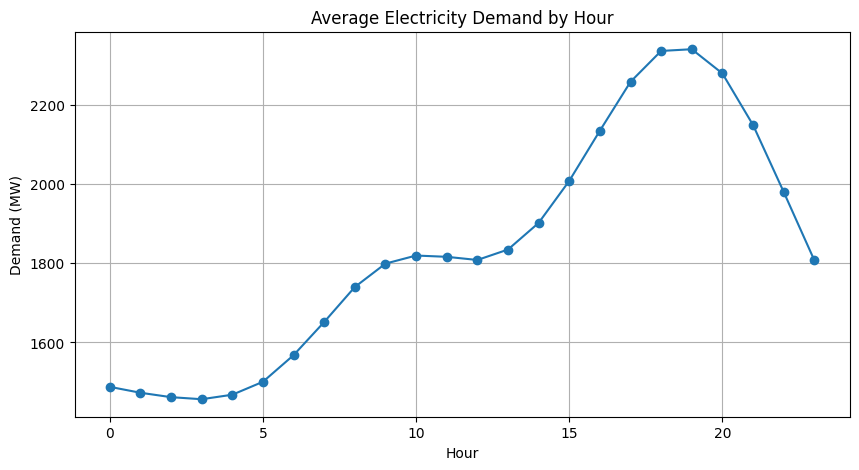

In [11]:
df["hour"] = df["timestamp"].dt.hour

hourly_demand = df.groupby("hour")["demand_mw"].mean()

plt.figure(figsize=(10,5))

hourly_demand.plot(marker="o")

plt.title("Average Electricity Demand by Hour")
plt.xlabel("Hour")
plt.ylabel("Demand (MW)")

plt.grid()
plt.show()

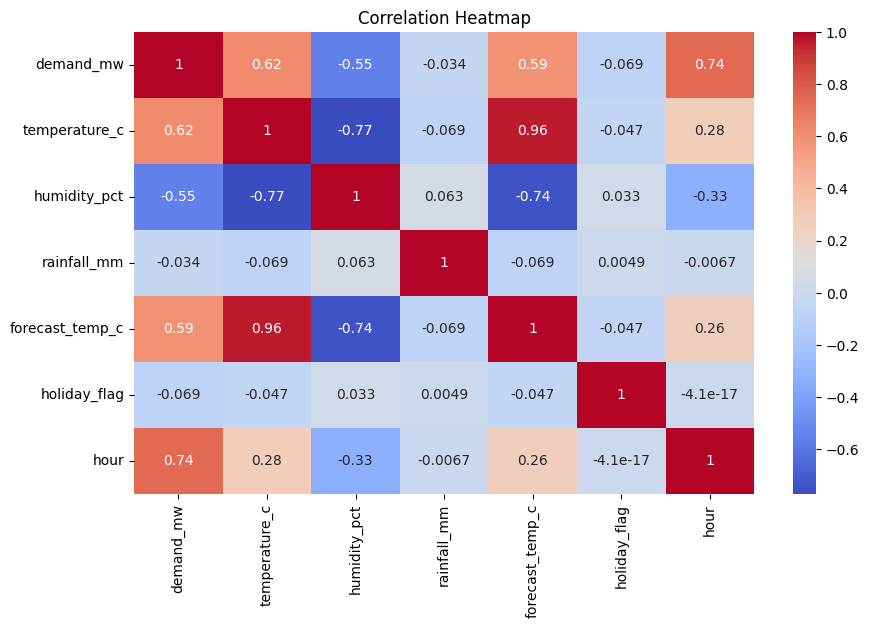

In [12]:
plt.figure(figsize=(10,6))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

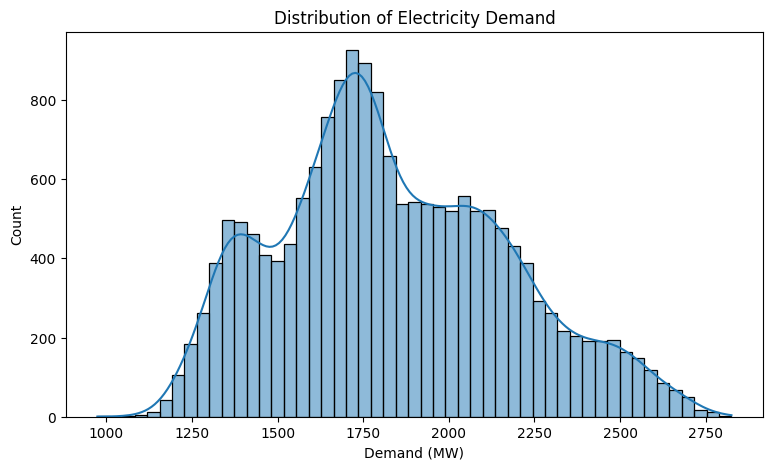

In [13]:
plt.figure(figsize=(9,5))

sns.histplot(df["demand_mw"], kde=True)

plt.title("Distribution of Electricity Demand")

plt.xlabel("Demand (MW)")

plt.show()

In [14]:
df["hour"] = df["timestamp"].dt.hour

df["dayofweek"] = df["timestamp"].dt.dayofweek

df["dayofyear"] = df["timestamp"].dt.dayofyear

df["month"] = df["timestamp"].dt.month

df["is_weekend"] = (
    df["dayofweek"] >= 5
).astype(int)

In [15]:
df["lag_24"] = df["demand_mw"].shift(24)

df["lag_48"] = df["demand_mw"].shift(48)

df["lag_168"] = df["demand_mw"].shift(168)

In [16]:
df["rolling_mean_24"] = (
    df["demand_mw"].shift(1).rolling(24).mean()
)

df["rolling_mean_168"] = (
    df["demand_mw"].shift(1).rolling(168).mean()
)

df = df.dropna().reset_index(drop=True)

display(df.head())

print("Final dataset shape:", df.shape)

,timestamp,demand_mw,temperature_c,humidity_pct,rainfall_mm,forecast_temp_c,holiday_flag,hour,dayofweek,dayofyear,month,is_weekend,lag_24,lag_48,lag_168,rolling_mean_24,rolling_mean_168
0,2023-07-08 00:00:00,1497.56,31.62,66.85,0.0,31.93,0.0,0,5,189,7,1,1627.54,1579.61,1459.38,1908.272500,1898.504048
1,2023-07-08 01:00:00,1492.70,31.21,60.44,0.0,29.69,0.0,1,5,189,7,1,1601.52,1616.37,1452.66,1902.856667,1898.731310
2,2023-07-08 02:00:00,1500.87,29.87,72.80,0.0,27.63,0.0,2,5,189,7,1,1453.83,1544.00,1540.38,1898.322500,1898.969643
3,2023-07-08 03:00:00,1459.64,30.60,72.94,0.0,30.09,0.0,3,5,189,7,1,1549.38,1622.76,1611.53,1900.282500,1898.734464
4,2023-07-08 04:00:00,1353.85,28.96,71.18,0.0,28.10,0.0,4,5,189,7,1,1476.12,1632.78,1419.52,1896.543333,1897.830357


Final dataset shape: (17376, 17)


In [17]:
features = [
    "lag_24",
    "lag_48",
    "lag_168",
    "rolling_mean_24",
    "rolling_mean_168",
    "hour",
    "dayofweek",
    "dayofyear",
    "month",
    "is_weekend",
    "holiday_flag",
    "temperature_c",
    "humidity_pct",
    "rainfall_mm",
    "forecast_temp_c"
]

X = df[features]

y = df["demand_mw"]

print("Input shape:", X.shape)

print("Output shape:", y.shape)

Input shape: (17376, 15)
Output shape: (17376,)


In [18]:
train = df[df["timestamp"] < "2025-04-01"]

test = df[df["timestamp"] >= "2025-04-01"]

X_train = train[features]

X_test = test[features]

y_train = train["demand_mw"]

y_test = test["demand_mw"]

print("Training rows:", len(X_train))

print("Testing rows:", len(X_test))

Training rows: 15192
Testing rows: 2184


In [19]:
ridge = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10)
)

ridge.fit(X_train, y_train)

ridge_pred = ridge.predict(X_test)

print("Ridge Regression completed")

Ridge Regression completed


In [20]:
rf = RandomForestRegressor(
    n_estimators=250,
    max_depth=18,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest completed")

Random Forest completed


In [21]:
gb = HistGradientBoostingRegressor(
    max_iter=250,
    learning_rate=0.06,
    max_leaf_nodes=25,
    random_state=42
)

gb.fit(X_train, y_train)

gb_pred = gb.predict(X_test)

print("Gradient Boosting completed")

Gradient Boosting completed


In [22]:
lgbm = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.035,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

lgbm.fit(X_train, y_train)

lgbm_pred = lgbm.predict(X_test)

print("LightGBM completed")

LightGBM completed


In [23]:
def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    mape = np.mean(
        np.abs((y_true - y_pred) / y_true)
    ) * 100

    return mae, rmse, mape

In [24]:
models = {
    "Ridge Regression": ridge_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred,
    "LightGBM": lgbm_pred
}

results = []

for name, prediction in models.items():

    mae, rmse, mape = evaluate_model(
        y_test.values,
        prediction
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values("MAPE"))

,Model,MAE,RMSE,MAPE
3,LightGBM,48.710816,61.980181,2.446483
2,Gradient Boosting,49.709315,63.146997,2.497601
1,Random Forest,55.322500,70.014842,2.795777
0,Ridge Regression,63.949820,80.265600,3.218925


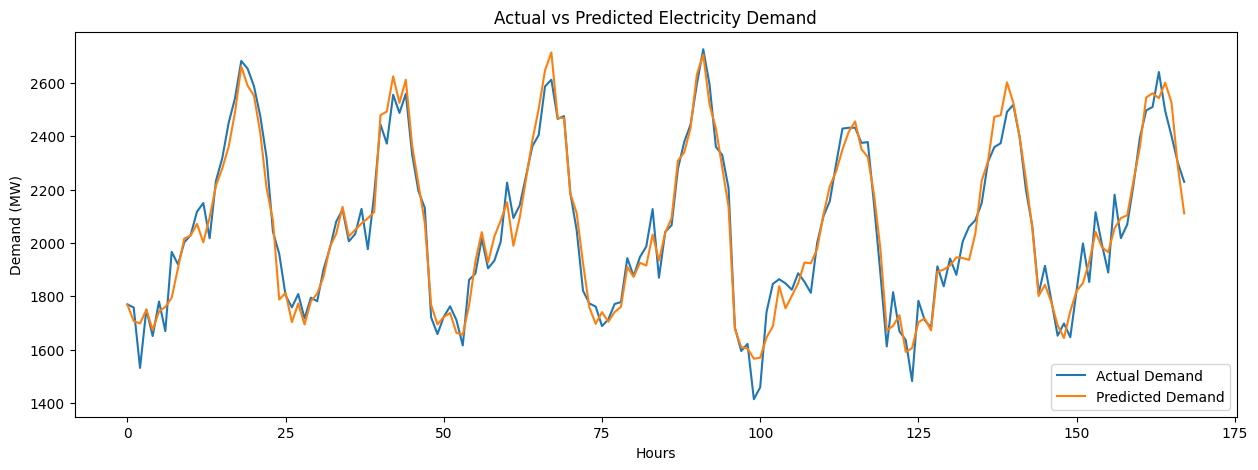

In [25]:
best_model = lgbm

best_pred = lgbm_pred

plt.figure(figsize=(15,5))

plt.plot(
    y_test.values[:168],
    label="Actual Demand"
)

plt.plot(
    best_pred[:168],
    label="Predicted Demand"
)

plt.title("Actual vs Predicted Electricity Demand")

plt.xlabel("Hours")

plt.ylabel("Demand (MW)")

plt.legend()

plt.show()

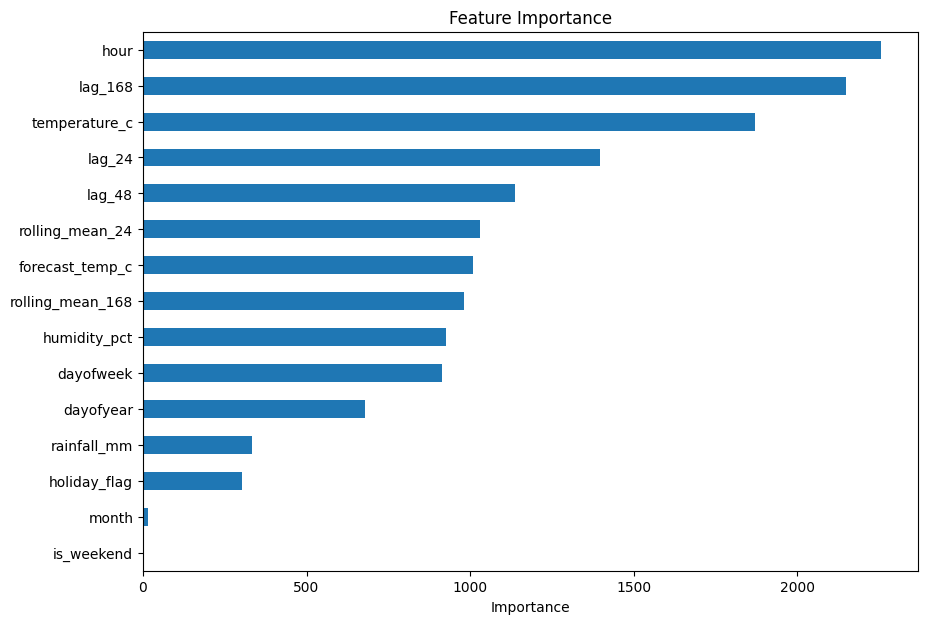

In [26]:
importance = pd.Series(
    lgbm.feature_importances_,
    index=features
).sort_values(ascending=True)

plt.figure(figsize=(10,7))

importance.plot(kind="barh")

plt.title("Feature Importance")

plt.xlabel("Importance")

plt.show()

In [27]:
history = df.copy().sort_values("timestamp").reset_index(drop=True)

future_predictions = []

last_timestamp = history["timestamp"].max()

for i in range(1, 25):

    next_time = last_timestamp + pd.Timedelta(hours=i)

    new_row = {
        "timestamp": next_time,
        "demand_mw": np.nan,
        "temperature_c": history["temperature_c"].iloc[-1],
        "humidity_pct": history["humidity_pct"].iloc[-1],
        "rainfall_mm": 0,
        "forecast_temp_c": history["forecast_temp_c"].iloc[-1],
        "holiday_flag": 0
    }

    temp_df = pd.concat(
        [history, pd.DataFrame([new_row])],
        ignore_index=True
    )

    temp_df["hour"] = temp_df["timestamp"].dt.hour
    temp_df["dayofweek"] = temp_df["timestamp"].dt.dayofweek
    temp_df["dayofyear"] = temp_df["timestamp"].dt.dayofyear
    temp_df["month"] = temp_df["timestamp"].dt.month
    temp_df["is_weekend"] = (temp_df["dayofweek"] >= 5).astype(int)

    demand = temp_df["demand_mw"]

    temp_df["lag_24"] = demand.shift(24)
    temp_df["lag_48"] = demand.shift(48)
    temp_df["lag_168"] = demand.shift(168)

    temp_df["rolling_mean_24"] = (
        demand.shift(1).rolling(24).mean()
    )

    temp_df["rolling_mean_168"] = (
        demand.shift(1).rolling(168).mean()
    )

    X_future = temp_df[features].iloc[[-1]]

    prediction = lgbm.predict(X_future)[0]

    new_row["demand_mw"] = prediction

    history = pd.concat(
        [history, pd.DataFrame([new_row])],
        ignore_index=True
    )

    future_predictions.append({
        "Timestamp": next_time,
        "Predicted_Demand_MW": prediction
    })

forecast_df = pd.DataFrame(future_predictions)

display(forecast_df)

,Timestamp,Predicted_Demand_MW
0,2025-07-01 00:00:00,1589.333535
1,2025-07-01 01:00:00,1551.308042
2,2025-07-01 02:00:00,1586.684833
3,2025-07-01 03:00:00,1586.442261
4,2025-07-01 04:00:00,1612.285560
5,2025-07-01 05:00:00,1671.639333
6,2025-07-01 06:00:00,1743.198895
7,2025-07-01 07:00:00,1767.563954
8,2025-07-01 08:00:00,1899.387535
9,2025-07-01 09:00:00,1944.759989


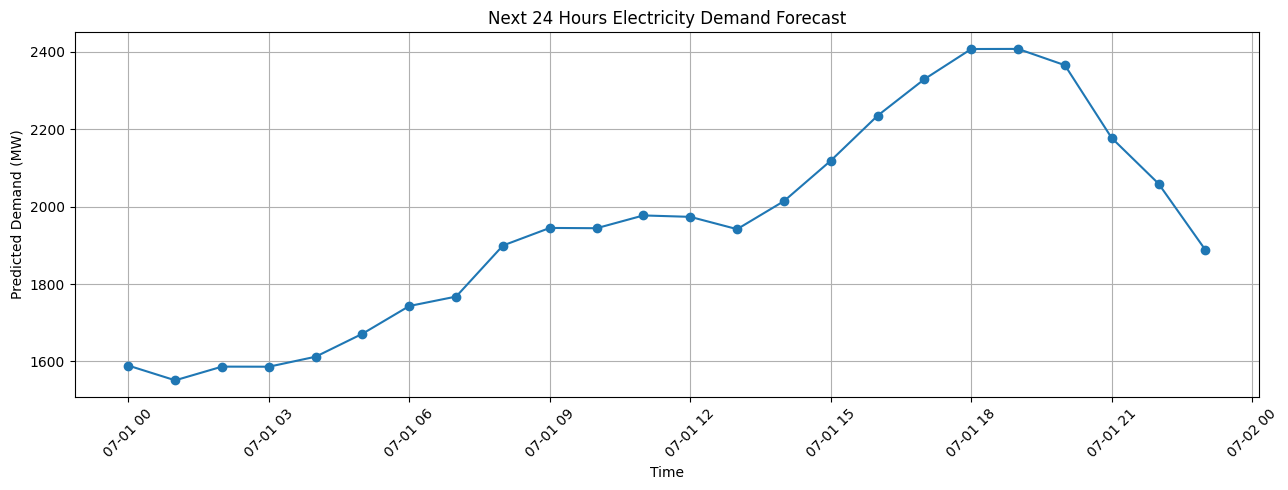

In [28]:
plt.figure(figsize=(13,5))

plt.plot(
    forecast_df["Timestamp"],
    forecast_df["Predicted_Demand_MW"],
    marker="o"
)

plt.title("Next 24 Hours Electricity Demand Forecast")

plt.xlabel("Time")

plt.ylabel("Predicted Demand (MW)")

plt.xticks(rotation=45)

plt.grid()

plt.tight_layout()

plt.show()

In [29]:
results_df.to_csv("model_comparison.csv", index=False)

forecast_df.to_csv("next_24_hours_forecast.csv", index=False)

print("Project completed successfully!")

print("Model comparison saved.")

print("24-hour forecast saved.")

Project completed successfully!
Model comparison saved.
24-hour forecast saved.
